In [1]:
import pandas as pd, numpy as np
import matplotlib.pyplot as plt
pd.set_option("display.float_format", "{:,.2f}".format)
pd.set_option("display.max_columns", 50)

orders   = pd.read_csv("Desktop/DATA ANALYST/DA PROJECT/e-commerce-profitability-analysis-kvrti/brightcart/data_raw/orders.csv", parse_dates=["order_date"])
mkt      = pd.read_csv("Desktop/DATA ANALYST/DA PROJECT/e-commerce-profitability-analysis-kvrti/brightcart/data_raw/marketing_spend.csv")
products = pd.read_csv("Desktop/DATA ANALYST/DA PROJECT/e-commerce-profitability-analysis-kvrti/brightcart/data_raw/products.csv")

def driver_table(df, by):
    g = df.groupby(by).agg(
        orders=("order_id", "count"),
        returned_orders=("is_returned", "sum"),
        gross=("gross_revenue", "sum"),
        discounts=("discount_amount", "sum"),
        refunds=("refund_amount", "sum"),
        net_revenue=("net_revenue", "sum"),
        product_cost=("product_cost", "sum"),
        shipping=("shipping_cost", "sum"),
        platform_fee=("platform_fee", "sum"),
        txn_fee=("transaction_fee", "sum"),
        profit=("profit", "sum"),
    )
    g["margin_pct"]       = g.profit / g.net_revenue * 100
    g["profit_per_order"] = g.profit / g.orders
    g["return_rate_pct"]  = g.returned_orders / g.orders * 100
    for c in ["discounts", "refunds", "product_cost", "shipping", "platform_fee", "txn_fee"]:
        g[c + "_%gross"] = g[c] / g.gross * 100
    g["profit_%gross"] = g.profit / g.gross * 100
    return g

# Sanity test on the whole dataset: must match the master totals
orders["all"] = "All"
print(driver_table(orders, "all")[["orders", "gross", "net_revenue", "profit", "margin_pct"]])


     orders      gross  net_revenue    profit  margin_pct
all                                                      
All    2000 277,969.13   236,318.37 56,333.83       23.84


                  orders  net_revenue    profit  margin_pct  profit_per_order
primary_category                                                             
Electronics          267    44,885.84 13,973.46       31.13             52.34
Toys                 257    33,595.68  8,786.25       26.15             34.19
Home & Kitchen       200    26,359.76  6,688.57       25.37             33.44
Food & Beverage      247    30,662.69  7,591.77       24.76             30.74
Sports               292    32,329.83  7,596.63       23.50             26.02
Clothing             293    31,383.13  6,272.48       19.99             21.41
Beauty               205    18,254.07  3,174.88       17.39             15.49
Books                239    18,847.37  2,249.79       11.94              9.41
                  discounts_%gross  refunds_%gross  product_cost_%gross  \
primary_category                                                          
Electronics                   7.40            7.71                38.0

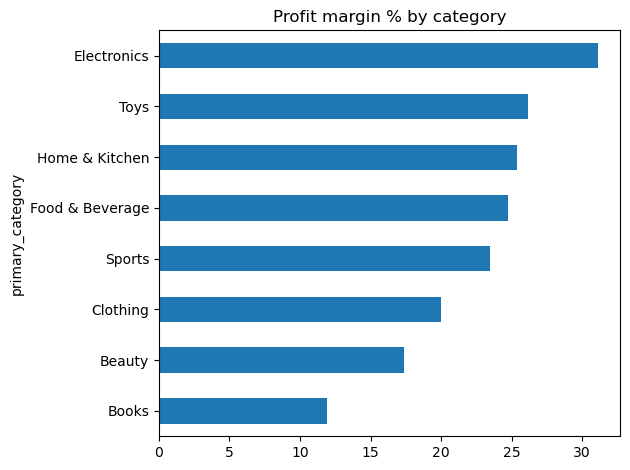

                 avg_price  avg_unit_cost  avg_ship_per_unit  \
category                                                       
Beauty               31.73          13.00               9.90   
Books                16.53           6.75               9.64   
Clothing             51.40          21.50              10.15   
Electronics          99.64          36.79              10.60   
Food & Beverage      59.42          23.19              10.38   
Home & Kitchen       64.49          25.19               9.66   
Sports               46.24          19.99               8.55   
Toys                 58.76          23.30               9.42   

                 catalog_gross_margin_%  ship_as_%_of_price  
category                                                     
Beauty                            59.04               31.19  
Books                             59.17               58.32  
Clothing                          58.18               19.74  
Electronics                       63.07          

In [4]:
cat = driver_table(orders, "primary_category").sort_values("margin_pct", ascending=False)
print(cat[["orders", "net_revenue", "profit", "margin_pct", "profit_per_order"]])

# What drives the difference? Compare driver % of gross
drivers = ["discounts_%gross", "refunds_%gross", "product_cost_%gross",
           "shipping_%gross", "platform_fee_%gross", "txn_fee_%gross", "profit_%gross"]
print(cat[drivers])

best, worst = cat.index[0], cat.index[-1]
gap = (cat.loc[worst, drivers] - cat.loc[best, drivers]).sort_values(ascending=False)
print(f"Worst ({worst}) minus Best ({best}), in percentage points of gross revenue:")
print(gap)

# Chart
cat["margin_pct"].plot(kind="barh", title="Profit margin % by category")
plt.gca().invert_yaxis(); plt.tight_layout()
plt.savefig("Desktop/DATA ANALYST/DA PROJECT/e-commerce-profitability-analysis-kvrti/brightcart/outputs/q1_margin_by_category.png", dpi=150); plt.show()

# Catalog benchmark (products file): price vs cost vs shipping per unit
prod = products.groupby("category").agg(
    avg_price=("selling_price", "mean"), avg_unit_cost=("unit_cost", "mean"),
    avg_ship_per_unit=("shipping_cost_per_unit", "mean"))
prod["catalog_gross_margin_%"] = (prod.avg_price - prod.avg_unit_cost) / prod.avg_price * 100
prod["ship_as_%_of_price"] = prod.avg_ship_per_unit / prod.avg_price * 100
print(prod)

cat.to_csv("Desktop/DATA ANALYST/DA PROJECT/e-commerce-profitability-analysis-kvrti/brightcart/outputs/q1_category_table.csv")


                 orders  net_revenue    profit  profit_per_order  margin_pct
channel                                                                     
Mobile App          589    71,893.39 21,393.30             36.32       29.76
Website             795    92,990.55 25,118.46             31.60       27.01
Social Commerce     197    21,929.37  3,370.54             17.11       15.37
Marketplace         419    49,505.06  6,451.53             15.40       13.03
                 discounts_%gross  refunds_%gross  product_cost_%gross  \
channel                                                                  
Mobile App                   6.66            6.44                39.73   
Website                      7.91            8.44                40.06   
Social Commerce              8.08            9.01                40.30   
Marketplace                  8.04            6.06                39.70   

                 shipping_%gross  platform_fee_%gross  txn_fee_%gross  \
channel             

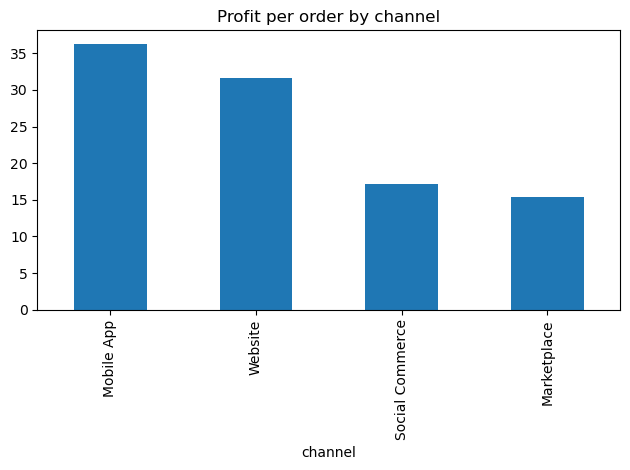

In [5]:
ch = driver_table(orders, "channel").sort_values("profit_per_order", ascending=False)
print(ch[["orders", "net_revenue", "profit", "profit_per_order", "margin_pct"]])
print(ch[["discounts_%gross", "refunds_%gross", "product_cost_%gross", "shipping_%gross",
          "platform_fee_%gross", "txn_fee_%gross", "profit_%gross"]])

# Average order value (AOV) per channel: explains part of profit/order
print(orders.groupby("channel")["gross_revenue"].mean())

# Cross-view: channel x category profit per order (heatmap-style)
xt = orders.pivot_table(index="primary_category", columns="channel",
                        values="profit", aggfunc="mean")
print(xt)

ch["profit_per_order"].plot(kind="bar", title="Profit per order by channel")
plt.tight_layout(); plt.savefig("Desktop/DATA ANALYST/DA PROJECT/e-commerce-profitability-analysis-kvrti/brightcart/outputs/q2_profit_per_order_channel.png", dpi=150); plt.show()
ch.to_csv("Desktop/DATA ANALYST/DA PROJECT/e-commerce-profitability-analysis-kvrti/brightcart/outputs/q2_channel_table.csv")


In [6]:
# Return rate
ret_cat = driver_table(orders, "primary_category")[["orders", "returned_orders", "return_rate_pct", "refunds"]]
ret_ch  = driver_table(orders, "channel")[["orders", "returned_orders", "return_rate_pct", "refunds"]]
print(ret_cat.sort_values("return_rate_pct", ascending=False))
print(ret_ch.sort_values("return_rate_pct", ascending=False))

# Category x channel return-rate matrix (small cells, treat as directional)
rr = orders.pivot_table(index="primary_category", columns="channel",
                        values="is_returned", aggfunc="mean") * 100
print(rr)

# Revenue lost to returns
gross_total    = orders.gross_revenue.sum()
revenue_lost   = orders.refund_amount.sum()              # money refunded
revenue_lost_g = orders.loc[orders.is_returned == 1, "gross_revenue"].sum()  # before discounts
print(f"Refunded revenue: {revenue_lost:,.2f}  ({revenue_lost/gross_total*100:.1f}% of gross)")

# Sunk costs on returned orders (cost you paid but got no revenue for)
ret = orders[orders.is_returned == 1]
sunk = (ret.product_cost + ret.shipping_cost + ret.platform_fee + ret.transaction_fee).sum()
print(f"Costs sunk on returned orders: {sunk:,.2f}")

# Margin impact of returns
margin_actual = orders.profit.sum() / orders.net_revenue.sum() * 100
margin_no_ret = (orders.profit.sum() + revenue_lost) / (orders.gross_revenue.sum() - orders.discount_amount.sum()) * 100
print(f"Margin actual {margin_actual:.1f}%  vs without returns {margin_no_ret:.1f}%")

# Return trend by month (ignore the partial edge months)
monthly = orders.groupby("order_month").agg(orders=("order_id", "count"), ret=("is_returned", "mean"))
print(monthly)


                  orders  returned_orders  return_rate_pct  refunds
primary_category                                                   
Electronics          267               23             8.61 4,078.27
Books                239               20             8.37 2,106.36
Clothing             293               24             8.19 3,209.21
Sports               292               21             7.19 2,008.44
Toys                 257               18             7.00 2,469.81
Home & Kitchen       200               12             6.00 2,340.10
Beauty               205               12             5.85   865.70
Food & Beverage      247               14             5.67 3,504.56
                 orders  returned_orders  return_rate_pct  refunds
channel                                                           
Social Commerce     197               18             9.14 2,381.65
Mobile App          589               43             7.30 5,324.17
Website             795               56            

Break-even ROAS: 4.93
                     spend      revenue  impressions  clicks  conversions  \
platform                                                                    
TikTok Ads       57,229.22 1,374,627.17     20750539  383269        18684   
Influencer       97,663.12 2,216,974.26      9990653  587501        28824   
Instagram Ads    65,154.02 1,024,639.06     11373438  306843        13863   
Google Ads      152,546.48 2,194,120.83     17529367  611740        32309   
Facebook Ads    106,451.93 1,218,572.43     16305609  331746        16968   
Email Marketing  24,461.37   117,681.45       636743   25971         1370   

                 roas   cpa  cpc  ctr_%  conv_rate_%  share_of_spend_%  \
platform                                                                 
TikTok Ads      24.02  3.06 0.15   1.85         4.87             11.37   
Influencer      22.70  3.39 0.17   5.88         4.91             19.40   
Instagram Ads   15.73  4.70 0.21   2.70         4.52             

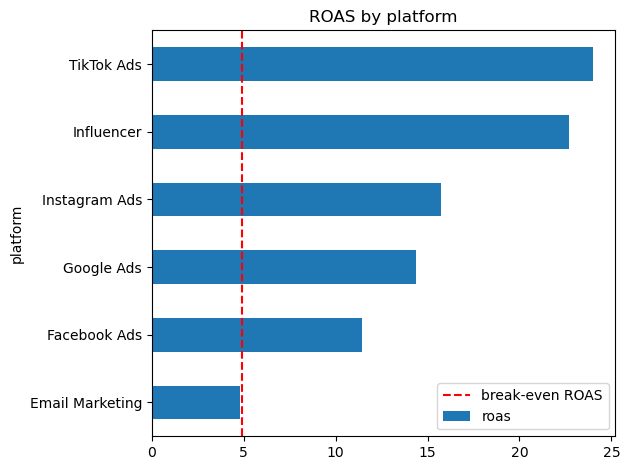

In [7]:
p = mkt.groupby("platform").agg(
    spend=("spend", "sum"), revenue=("revenue_attributed", "sum"),
    impressions=("impressions", "sum"), clicks=("clicks", "sum"),
    conversions=("conversions", "sum"))
p["roas"]      = p.revenue / p.spend
p["cpa"]       = p.spend / p.conversions
p["cpc"]       = p.spend / p.clicks
p["ctr_%"]     = p.clicks / p.impressions * 100
p["conv_rate_%"] = p.conversions / p.clicks * 100
p["share_of_spend_%"] = p.spend / p.spend.sum() * 100

# Break-even ROAS: attributed revenue is gross-like, so use margin on gross
margin_gross  = orders.profit.sum() / orders.gross_revenue.sum()      # about 0.203
breakeven     = 1 / margin_gross                                      # about 4.9
p["profit_adj_roas"]  = p.roas * margin_gross                          # below 1 = losing money
p["profit_after_ads"] = p.revenue * margin_gross - p.spend
print(f"Break-even ROAS: {breakeven:.2f}")
print(p.sort_values("roas", ascending=False))

# Month-level view: how often is each platform below break-even or below 1?
mkt["below_1"]         = mkt.roas < 1
mkt["below_breakeven"] = mkt.roas < breakeven
print(mkt.groupby("platform")[["below_1", "below_breakeven"]].sum())
print(mkt[mkt.roas < 1][["month", "platform", "spend", "roas"]])

# Diminishing returns check: does ROAS fall when monthly spend is higher?
for name, d in mkt.groupby("platform"):
    print(f"{name:16s} corr(spend, roas) = {d.spend.corr(d.roas):.2f}")

p["roas"].sort_values().plot(kind="barh", title="ROAS by platform")
plt.axvline(breakeven, color="red", linestyle="--", label="break-even ROAS"); plt.legend()
plt.tight_layout(); plt.savefig("Desktop/DATA ANALYST/DA PROJECT/e-commerce-profitability-analysis-kvrti/brightcart/outputs/q4_roas.png", dpi=150); plt.show()
p.to_csv("Desktop/DATA ANALYST/DA PROJECT/e-commerce-profitability-analysis-kvrti/brightcart/outputs/q4_platform_table.csv")


In [8]:
BASE_YEAR  = "2025"
MAX_CUT    = 0.50
protected  = []            # e.g. ["2025-11", "2025-12"] if you decide to protect peak months

base = mkt[mkt.month.str.startswith(BASE_YEAR)].copy()
target = 0.20 * base.spend.sum()
print(f"Base spend {base.spend.sum():,.0f}  | cut target {target:,.0f}")

# Check seasonality before deciding what to protect
print(orders.groupby("order_month").size().tail(14))

base["pa_roas"] = base.revenue_attributed * margin_gross / base.spend
base = base.sort_values("roas")                 # worst return first
base["cut"] = 0.0
remaining = target
for idx, row in base.iterrows():
    if remaining <= 0:
        break
    if row.month in protected:
        continue
    c = min(row.spend * MAX_CUT, remaining)
    base.loc[idx, "cut"] = c
    remaining -= c

print(f"Planned cut {base.cut.sum():,.0f}  (leftover {remaining:,.0f})")
base["new_spend"] = base.spend - base.cut

# If leftover > 0, raise MAX_CUT slightly or unprotect a month, then rerun.

# Summaries
print(base.groupby("platform")[["spend", "cut", "new_spend"]].sum())
print(base.pivot_table(index="platform", columns="month", values="cut", aggfunc="sum").round(0))

# Estimated impact (assumes the cut platform-months keep earning their average ROAS)
base["revenue_lost"] = base.cut * base.roas
base["profit_lost"]  = base.revenue_lost * margin_gross
base["net_effect"]   = base.profit_lost - base.cut      # negative = the cut still helps
print("Attributed revenue at risk:", round(base.revenue_lost.sum()))
print("Profit at risk:", round(base.profit_lost.sum()), "vs spend saved:", round(base.cut.sum()))

base.to_csv("Desktop/DATA ANALYST/DA PROJECT/e-commerce-profitability-analysis-kvrti/brightcart/outputs/budget_cut_plan.csv", index=False)
base.sort_values("cut", ascending=False).head(15)[["month", "platform", "spend", "roas", "cut"]]


Base spend 251,925  | cut target 50,385
order_month
2024-12    109
2025-01    112
2025-02    100
2025-03    128
2025-04    107
2025-05    153
2025-06    155
2025-07    173
2025-08    159
2025-09    125
2025-10     91
2025-11     65
2025-12     32
2026-01      3
dtype: int64
Planned cut 50,385  (leftover 0)
                    spend       cut  new_spend
platform                                      
Email Marketing 12,531.16  6,265.58   6,265.58
Facebook Ads    52,474.17 17,610.65  34,863.52
Google Ads      75,992.13 11,669.59  64,322.54
Influencer      51,371.50  7,421.50  43,950.00
Instagram Ads   31,749.95  5,754.22  25,995.74
TikTok Ads      27,805.99  1,663.45  26,142.54
month            2025-01  2025-02  2025-03  2025-04  2025-05  2025-06  \
platform                                                                
Email Marketing   365.00   362.00   553.00   341.00   375.00   647.00   
Facebook Ads    1,184.00 1,713.00 2,116.00     0.00 1,303.00     0.00   
Google Ads      1,210.00

,month,platform,spend,roas,cut
133,2025-11,Facebook Ads,"6,884.20",4.44,"3,442.10"
120,2025-09,Google Ads,"6,501.13",3.84,"3,250.57"
108,2025-07,Google Ads,"5,843.74",4.27,"2,921.87"
84,2025-03,Google Ads,"4,709.29",3.32,"2,354.64"
119,2025-08,Influencer,"4,692.08",11.65,"2,346.04"
77,2025-01,Influencer,"4,482.46",3.78,"2,241.23"
127,2025-10,Facebook Ads,"4,378.84",7.76,"2,189.42"
115,2025-08,Facebook Ads,"4,299.84",9.20,"2,149.92"
85,2025-03,Facebook Ads,"4,232.78",4.60,"2,116.39"
121,2025-09,Facebook Ads,"3,877.76",2.51,"1,938.88"
